# 05 · 五个指标：同一个 8 人例子，公式到代码

详细推导见 `因果推断理论/7.Metrics.md`。本页所有数值都是教学例子，不用于估计真实业务效果。

- **lift curve**：$L=R_1/N_1-R_0/N_0$，单位为选中人群转化率差。
- **uplift/gain curve**：$G=qL$，单位为每名待选人的累计增量。
- **AUUC**：$\int G(q)dq$，这里不做 perfect normalization。
- **Qini curve**：$Q=(R_1-R_0N_1/N_0)/n$。
- **Qini score**：$\int Q(q)dq-Q(1)/2$。

相对 lift $L/L(1)$、HT gain 与传统 gain 均另外标注，不能混成同一指标。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'criteo_uplift').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from criteo_uplift.runtime import configure_runtime
configure_runtime()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from criteo_uplift.results import result_directory
FIG = ROOT/'artifacts/extension_figures'
FIG.mkdir(exist_ok=True)


In [2]:
from criteo_uplift.evaluation import uplift_curve, ranking_metrics
from fractions import Fraction as F
t = np.array([1,0,1,0,1,0,1,0])
y = np.array([1,0,1,0,0,1,1,0])
scores = np.arange(8,0,-1)/10
curve = uplift_curve(y,t,scores,e=.5)
metrics = ranking_metrics(y,t,scores,e=.5)
display(pd.DataFrame({'rank':np.arange(1,9),'score':scores,'treatment':t,'conversion':y}))
display(curve[['n_selected','fraction','n_treatment','n_control','responses_treatment','responses_control','cumulative_lift','relative_lift','gain_plugin','qini_traditional','gain_ht']])

,rank,score,treatment,conversion
0,1,0.8,1,1
1,2,0.7,0,0
2,3,0.6,1,1
3,4,0.5,0,0
4,5,0.4,1,0
5,6,0.3,0,1
6,7,0.2,1,1
7,8,0.1,0,0


,n_selected,fraction,n_treatment,n_control,responses_treatment,responses_control,cumulative_lift,relative_lift,gain_plugin,qini_traditional,gain_ht
0,0,0.000,0,0,0.0,0.0,NaN,NaN,0.000000,NaN,0.00
1,1,0.125,1,0,1.0,0.0,NaN,NaN,NaN,NaN,0.25
2,2,0.250,1,1,1.0,0.0,1.000000,2.000000,0.250000,0.125000,0.25
3,3,0.375,2,1,2.0,0.0,1.000000,2.000000,0.375000,0.250000,0.50
4,4,0.500,2,2,2.0,0.0,1.000000,2.000000,0.500000,0.250000,0.50
5,5,0.625,3,2,2.0,0.0,0.666667,1.333333,0.416667,0.250000,0.50
6,6,0.750,3,3,2.0,1.0,0.333333,0.666667,0.250000,0.125000,0.25
7,7,0.875,4,3,3.0,1.0,0.416667,0.833333,0.364583,0.208333,0.50
8,8,1.000,4,4,3.0,1.0,0.500000,1.000000,0.500000,0.250000,0.50


## 精确分数复算：独立于浮点实现

累计曲线的原点取 0；第一人没有对照，传统 gain/Qini 初始点不可估，积分用原点连到 $q=1/4$。下方使用 Python `Fraction` 逐段计算，不依赖浮点四舍五入。

传统 AUUC 参照线是 $q/2$，Qini 参照线是 $q/4$。相同排序、不同纵轴，面积自然不同。

In [3]:
q = [F(0),F(1,4),F(3,8),F(1,2),F(5,8),F(3,4),F(7,8),F(1)]
g = [F(0),F(1,4),F(3,8),F(1,2),F(5,12),F(1,4),F(35,96),F(1,2)]
qini = [F(0),F(1,8),F(1,4),F(1,4),F(1,4),F(1,8),F(5,24),F(1,4)]
def trapezoids(x,y):
    return [(x[i]-x[i-1])*(y[i]+y[i-1])/2 for i in range(1,len(x))]
g_areas, q_areas = trapezoids(q,g), trapezoids(q,qini)
display(pd.DataFrame({'q_left':list(map(str,q[:-1])),'q_right':list(map(str,q[1:])),
                      'gain_trapezoid':list(map(str,g_areas)),'qini_trapezoid':list(map(str,q_areas))}))
exact = {'auuc_plugin':sum(g_areas),'auuc_plugin_centered':sum(g_areas)-F(1,4),
         'qini_score_traditional':sum(q_areas)-F(1,8), 'auuc_ht':F(3,8),'qini_ht':F(1,8)}
assert exact['auuc_plugin'] == F(81,256)
assert exact['qini_score_traditional'] == F(19,384)
for name,value in exact.items(): np.testing.assert_allclose(metrics[name],float(value),rtol=0,atol=1e-14)
display(pd.DataFrame([{'metric':k,'exact':str(v),'decimal':float(v),'code':metrics[k]} for k,v in exact.items()]))

,q_left,q_right,gain_trapezoid,qini_trapezoid
0,0,1/4,1/32,1/64
1,1/4,3/8,5/128,3/128
2,3/8,1/2,7/128,1/32
3,1/2,5/8,11/192,1/32
4,5/8,3/4,1/24,3/128
5,3/4,7/8,59/1536,1/48
6,7/8,1,83/1536,11/384


,metric,exact,decimal,code
0,auuc_plugin,81/256,0.316406,0.316406
1,auuc_plugin_centered,17/256,0.066406,0.066406
2,qini_score_traditional,19/384,0.049479,0.049479
3,auuc_ht,3/8,0.375000,0.375000
4,qini_ht,1/8,0.125000,0.125000


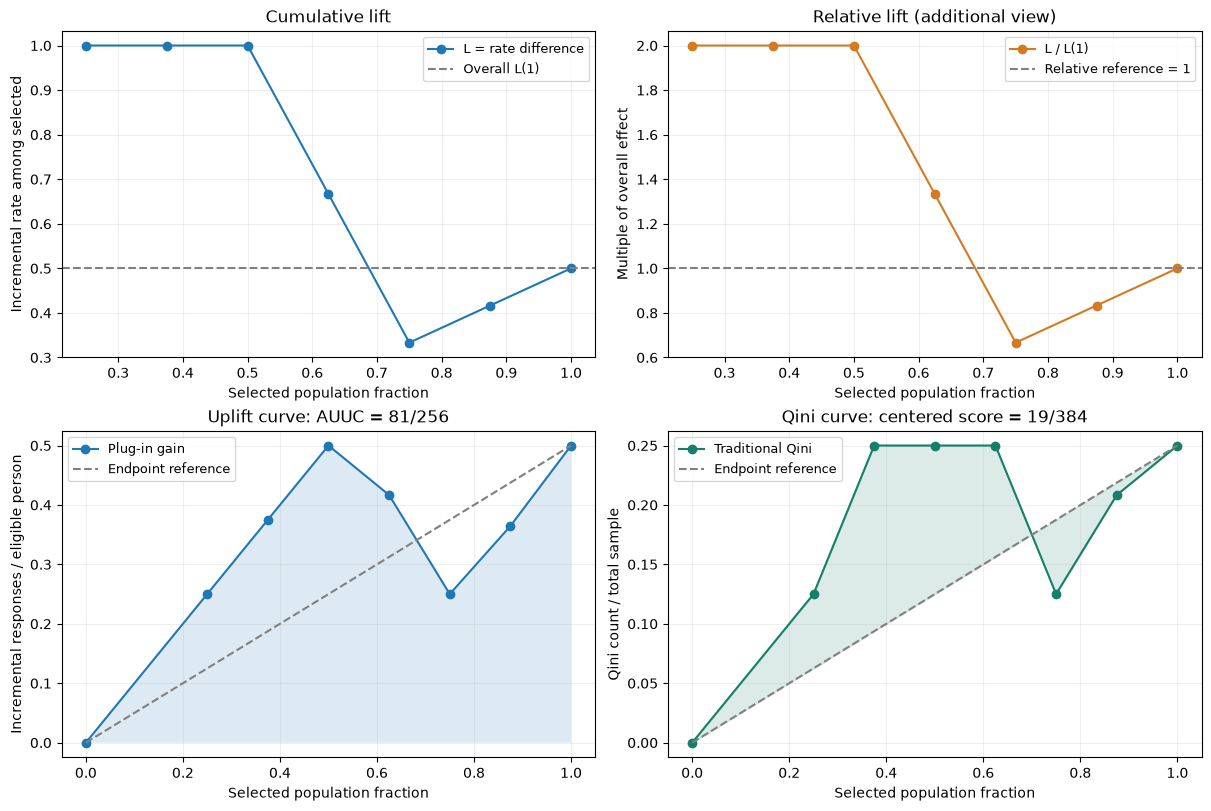

In [4]:
fig,axes=plt.subplots(2,2,figsize=(12,8),layout='constrained')
axes[0,0].plot(curve.fraction,curve.cumulative_lift,'o-',label='L = rate difference')
axes[0,0].axhline(.5,ls='--',color='gray',label='Overall L(1)')
axes[0,0].set(title='Cumulative lift',ylabel='Incremental rate among selected')
axes[0,1].plot(curve.fraction,curve.relative_lift,'o-',color='#d47a20',label='L / L(1)')
axes[0,1].axhline(1,ls='--',color='gray',label='Relative reference = 1')
axes[0,1].set(title='Relative lift (additional view)',ylabel='Multiple of overall effect')
axes[1,0].plot(list(map(float,q)),list(map(float,g)),'o-',label='Plug-in gain')
axes[1,0].fill_between(list(map(float,q)),list(map(float,g)),alpha=.15)
axes[1,0].plot([0,1],[0,.5],'--',color='gray',label='Endpoint reference')
axes[1,0].set(title='Uplift curve: AUUC = 81/256',ylabel='Incremental responses / eligible person')
axes[1,1].plot(list(map(float,q)),list(map(float,qini)),'o-',color='#167f67',label='Traditional Qini')
axes[1,1].plot([0,1],[0,.25],'--',color='gray',label='Endpoint reference')
axes[1,1].fill_between(list(map(float,q)),list(map(float,qini)),[float(x/4) for x in q],alpha=.15,color='#167f67')
axes[1,1].set(title='Qini curve: centered score = 19/384',ylabel='Qini count / total sample')
for ax in axes.flat:
    ax.set_xlabel('Selected population fraction');ax.legend(fontsize=9);ax.grid(alpha=.2)
fig.savefig(FIG/'worked_metrics.png',dpi=160)
plt.show()

## HT 为什么不同？

$z=(2,0,2,0,0,-2,2,0)$。固定 $e=1/2$ 时，首行也可以计算 HT；传统组间差需要两臂。两种曲线在全体处理比例吻合时终点相同，中途依然可能不同。

下面两条曲线估计同一总体策略目标，但有限样本权重不同。不要把一条曲线的面积和另一条的随机参照混用。

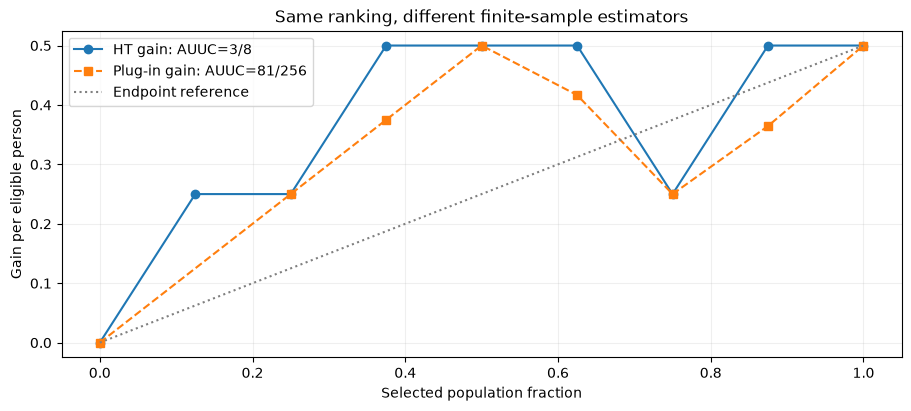

In [5]:
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
ax.plot(curve.fraction,curve.gain_ht,'o-',label='HT gain: AUUC=3/8')
ax.plot(list(map(float,q)),list(map(float,g)),'s--',label='Plug-in gain: AUUC=81/256')
ax.plot([0,1],[0,.5],':',color='gray',label='Endpoint reference')
ax.set(xlabel='Selected population fraction',ylabel='Gain per eligible person',title='Same ranking, different finite-sample estimators')
ax.legend();ax.grid(alpha=.2)
fig.savefig(FIG/'ht_vs_plugin.png',dpi=160);plt.show()

## 真实结果在下一页

这里的完美转化差来自人为构造的 8 行数据，不能推算实际收益。真实实验中我们使用 20% HT 主指标，并报告配对 bootstrap、AUUC/Qini、模型训练稳定性与事件数。全部曲线积分使用完整前缀，只有绘图做降采样。